In [ ]:
"""BAI THUC HANH 1: RED WINE QUALITY"""

In [1]:
"""Nhiệm vụ 1. Thống kê mô tả dữ liệu"""

'Nhiệm vụ 1. Thống kê mô tả dữ liệu'

In [13]:
import numpy as np
import pandas as pd
from scipy import stats

import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
"""Đọc dữ liệu"""
df_wine = pd.read_csv("winequality-red.csv", sep=",")
display(df_wine.head())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [11]:
"""Khám phá dữ liệu ban đầu"""
# Kích thước dữ liệu: số dòng và số cột
print("Kích thước dữ liệu:", df_wine.shape)

# Tên các cột
print("\nTên các cột:")
print(df_wine.columns.tolist())

# Kiểu dữ liệu
print("\nThông tin dữ liệu:")
df_wine.info()

# Thống kê mô tả tổng quát
display(df_wine.describe())

Kích thước dữ liệu: (1599, 12)

Tên các cột:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

Thông tin dữ liệu:
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   f

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [14]:
# Chỉ lấy các cột dữ liệu số
numeric_wine = df_wine.select_dtypes(include=np.number)

# Mean
mean_wine = np.mean(numeric_wine, axis=0)

# Median
median_wine = np.median(numeric_wine, axis=0)

# Mode: giá trị xuất hiện nhiều nhất
mode_wine = numeric_wine.mode().iloc[0]

# Variance: phương sai mẫu
variance_wine = np.var(numeric_wine, axis=0, ddof=1)

# Standard deviation: độ lệch chuẩn mẫu
std_wine = np.std(numeric_wine, axis=0, ddof=1)

# Range = Max - Min
range_wine = np.max(numeric_wine, axis=0) - np.min(
    numeric_wine, axis=0
)

# Percentile: các phân vị 10%, 25%, 50%, 75%, 90%
percentile_wine = np.percentile(
    numeric_wine, [10, 25, 50, 75, 90], axis=0
)

# Quartiles: Q1, Q2, Q3
q1_wine = np.percentile(numeric_wine, 25, axis=0)
q2_wine = np.percentile(numeric_wine, 50, axis=0)
q3_wine = np.percentile(numeric_wine, 75, axis=0)

# IQR = Q3 - Q1
iqr_wine = q3_wine - q1_wine

# Tổng hợp kết quả thành bảng
stats_wine = pd.DataFrame({
    "Mean": mean_wine,
    "Median": median_wine,
    "Mode": mode_wine,
    "Variance": variance_wine,
    "Standard Deviation": std_wine,
    "Range": range_wine,
    "Q1": q1_wine,
    "Q2 (Median)": q2_wine,
    "Q3": q3_wine,
    "IQR": iqr_wine
}, index=numeric_wine.columns)

display(stats_wine.round(4))

,Mean,Median,Mode,Variance,Standard Deviation,Range,Q1,Q2 (Median),Q3,IQR
fixed acidity,8.3196,7.9000,7.2000,3.0314,1.7411,11.3000,7.1000,7.9000,9.2000,2.1000
volatile acidity,0.5278,0.5200,0.6000,0.0321,0.1791,1.4600,0.3900,0.5200,0.6400,0.2500
citric acid,0.2710,0.2600,0.0000,0.0379,0.1948,1.0000,0.0900,0.2600,0.4200,0.3300
residual sugar,2.5388,2.2000,2.0000,1.9879,1.4099,14.6000,1.9000,2.2000,2.6000,0.7000
chlorides,0.0875,0.0790,0.0800,0.0022,0.0471,0.5990,0.0700,0.0790,0.0900,0.0200
free sulfur dioxide,15.8749,14.0000,6.0000,109.4149,10.4602,71.0000,7.0000,14.0000,21.0000,14.0000
total sulfur dioxide,46.4678,38.0000,28.0000,1082.1024,32.8953,283.0000,22.0000,38.0000,62.0000,40.0000
density,0.9967,0.9968,0.9972,0.0000,0.0019,0.0136,0.9956,0.9968,0.9978,0.0022
pH,3.3111,3.3100,3.3000,0.0238,0.1544,1.2700,3.2100,3.3100,3.4000,0.1900
sulphates,0.6581,0.6200,0.6000,0.0287,0.1695,1.6700,0.5500,0.6200,0.7300,0.1800


In [15]:
"""Xem riêng các percentile"""
percentile_table_wine = pd.DataFrame(
    percentile_wine.T,
    index=numeric_wine.columns,
    columns=[
        "P10",
        "P25",
        "P50",
        "P75",
        "P90"
    ]
)

display(percentile_table_wine.round(4))

,P10,P25,P50,P75,P90
fixed acidity,6.5000,7.1000,7.9000,9.2000,10.7000
volatile acidity,0.3100,0.3900,0.5200,0.6400,0.7450
citric acid,0.0100,0.0900,0.2600,0.4200,0.5220
residual sugar,1.7000,1.9000,2.2000,2.6000,3.6000
chlorides,0.0600,0.0700,0.0790,0.0900,0.1090
free sulfur dioxide,5.0000,7.0000,14.0000,21.0000,31.0000
total sulfur dioxide,14.0000,22.0000,38.0000,62.0000,93.2000
density,0.9946,0.9956,0.9968,0.9978,0.9991
pH,3.1200,3.2100,3.3100,3.4000,3.5100
sulphates,0.5000,0.5500,0.6200,0.7300,0.8500


In [16]:
for column in numeric_wine.columns:
    values = numeric_wine[column].dropna()

    mode_result = stats.mode(
        values,
        keepdims=False
    )

    print(f"\nCột: {column}")
    print("Mode:", mode_result.mode)
    print("Số lần xuất hiện:", mode_result.count)

    print("Mean:", stats.tmean(values))
    print("Variance:", stats.tvar(values))
    print("Standard deviation:", stats.tstd(values))


Cột: fixed acidity
Mode: 7.2
Số lần xuất hiện: 67
Mean: 8.31963727329581
Variance: 3.0314163889978163
Standard deviation: 1.7410963181276953

Cột: volatile acidity
Mode: 0.6
Số lần xuất hiện: 47
Mean: 0.5278205128205128
Variance: 0.032062377651551614
Standard deviation: 0.17905970415353537

Cột: citric acid
Mode: 0.0
Số lần xuất hiện: 132
Mean: 0.2709756097560976
Variance: 0.0379474831344058
Standard deviation: 0.19480113740531857

Cột: residual sugar
Mode: 2.0
Số lần xuất hiện: 156
Mean: 2.53880550343965
Variance: 1.9878971329859632
Standard deviation: 1.4099280595072796

Cột: chlorides
Mode: 0.08
Số lần xuất hiện: 66
Mean: 0.08746654158849279
Variance: 0.0022151426533009912
Standard deviation: 0.0470653020100901

Cột: free sulfur dioxide
Mode: 6.0
Số lần xuất hiện: 138
Mean: 15.874921826141339
Variance: 109.41488383305898
Standard deviation: 10.460156969809725

Cột: total sulfur dioxide
Mode: 28.0
Số lần xuất hiện: 43
Mean: 46.46779237023139
Variance: 1082.1023725325824
Standard dev

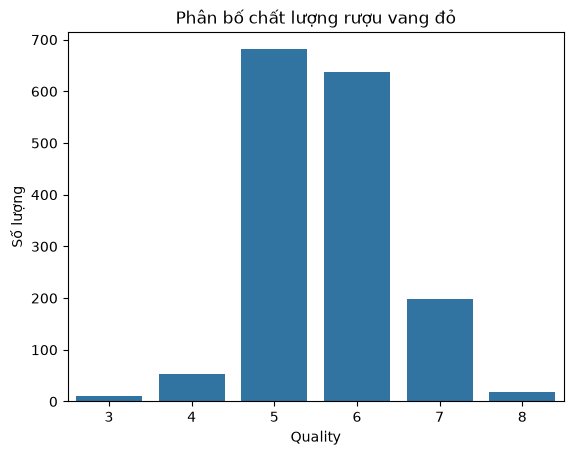

In [17]:
"""Biểu đồ khám phá dữ liệu"""
# Phân bố điểm chất lượng rượu
sns.countplot(data=df_wine, x="quality")

plt.title("Phân bố chất lượng rượu vang đỏ")
plt.xlabel("Quality")
plt.ylabel("Số lượng")
plt.show()

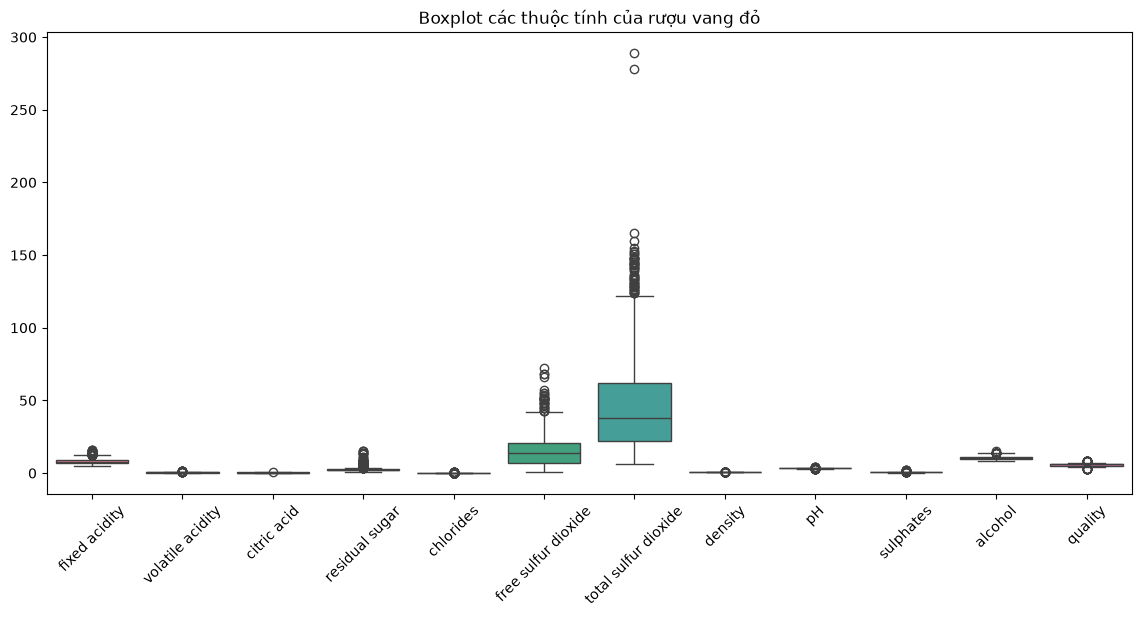

In [18]:
# Boxplot của các đặc trưng
plt.figure(figsize=(14, 6))

sns.boxplot(data=numeric_wine)

plt.title("Boxplot các thuộc tính của rượu vang đỏ")
plt.xticks(rotation=45)
plt.show()

In [19]:
"""Nhiệm vụ 2: Khám phá và xử lý dữ liệu"""
# Xem 5 dòng đầu
display(df_wine.head())

# Kiểm tra kích thước
print("Kích thước ban đầu:", df_wine.shape)

# Kiểm tra kiểu dữ liệu
print(df_wine.dtypes)

# Kiểm tra dữ liệu thiếu
print(df_wine.isnull().sum())

# Kiểm tra số dòng trùng lặp
print("Số dòng trùng lặp:", df_wine.duplicated().sum())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


Kích thước ban đầu: (1599, 12)
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64
Số dòng trùng lặp: 240


In [20]:
"""Loại bỏ dữ liệu trùng lặp"""
df_wine = df_wine.drop_duplicates().copy()

df_wine = df_wine.reset_index(drop=True)

print("Kích thước sau khi loại bỏ trùng lặp:", df_wine.shape)
print("Số dòng trùng lặp còn lại:", df_wine.duplicated().sum())

Kích thước sau khi loại bỏ trùng lặp: (1359, 12)
Số dòng trùng lặp còn lại: 0


In [21]:
"""Thay thế dữ liệu và thay đổi định dạng"""
# Chuyển tất cả các cột sang kiểu số nếu có thể
for column in df_wine.columns:
    df_wine[column] = pd.to_numeric(
        df_wine[column],
        errors="coerce"
    )

# Kiểm tra lại kiểu dữ liệu
print(df_wine.dtypes)

# Kiểm tra giá trị không hợp lệ phát sinh
print("Số giá trị thiếu sau chuyển đổi:")
print(df_wine.isnull().sum())

fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object
Số giá trị thiếu sau chuyển đổi:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


In [22]:
numeric_columns = df_wine.select_dtypes(
    include=np.number
).columns

df_wine[numeric_columns] = df_wine[numeric_columns].fillna(
    df_wine[numeric_columns].median()
)

print(df_wine.isnull().sum())

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


In [23]:
"""Xử lý dữ liệu thiếu và lưu dữ liệu sạch"""
print("Dữ liệu thiếu trước xử lý:")
print(df_wine.isnull().sum().sum())

# Xóa các dòng không thể xử lý nếu có dữ liệu vẫn thiếu
df_wine = df_wine.dropna().reset_index(drop=True)

print("Dữ liệu thiếu sau xử lý:")
print(df_wine.isnull().sum().sum())

# Lưu dữ liệu sau xử lý
df_wine.to_csv(
    "red_wine_cleaned.csv",
    index=False
)

print("Đã lưu file red_wine_cleaned.csv")

Dữ liệu thiếu trước xử lý:
0
Dữ liệu thiếu sau xử lý:
0
Đã lưu file red_wine_cleaned.csv
